# step 1

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('project.csv')

In [3]:
df.shape

(235795, 56)

In [4]:
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


# step 2 :check and clean data

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  object 
 1   URL                         235795 non-null  object 
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  object 
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  object 
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation

In [6]:
df.isnull().sum().sum()

np.int64(0)

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['label'].value_counts()

label
1    134850
0    100945
Name: count, dtype: int64

In [9]:
df.select_dtypes(include='object').columns
# got 5 object

Index(['FILENAME', 'URL', 'Domain', 'TLD', 'Title'], dtype='object')

In [10]:
df_clean = df.drop(columns=['FILENAME', 'URL', 'Domain', 'Title'])
df_clean.shape

(235795, 52)

In [11]:
df['URL'].nunique()

235370

In [12]:
df['Domain'].nunique()

220086

In [13]:
df['Title'].nunique()

197874

In [14]:
df['TLD'].nunique()

695

# step 3 :Convert the TLD to a number and store it in a new column.

In [15]:
le = LabelEncoder()

In [16]:
df['TLD_encoded'] = le.fit_transform(df['TLD'])

In [17]:
df[['TLD','TLD_encoded']].head(10)
# Same code name = same number

,TLD,TLD_encoded
0,com,231
1,de,254
2,uk,647
3,com,231
4,org,503
5,org,503
6,com,231
7,com,231
8,in,368
9,org,503


In [18]:
df_clean = df_clean.drop(columns=['TLD'])
df_clean.shape

(235795, 51)

# step 4

In [19]:
df_clean['TLD_encoded'] = df['TLD_encoded']
df = df_clean.copy()

print(df.columns.tolist())

['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label', 'TLD_encoded']


In [20]:
# before drop label is 52

X = df.drop(columns=['label'])
y = df['label']
# after is 51
# A row that only displays a label.
print("X shape:", X.shape)
print("y shape", y.shape)

X shape: (235795, 51)
y shape (235795,)


# step 5  Train/Test Split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

# stratify=y （Ensure that the training set and the test set have the same number of samples.）

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (188636, 51)
X_test shape: (47159, 51)
y_train shape: (188636,)
y_test shape: (47159,)


In [22]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Done scaling")
print(X_train_scaled[:2])

Done scaling
[[-0.2582902  -0.48816772 -0.05287945  0.74445584  0.71408399  1.04458853
   0.61394113  0.39167177 -0.27544102 -0.04522324 -0.01283941 -0.03592044
  -0.30284789 -0.4687109  -0.1502932  -0.40442994 -0.06329513 -0.15228304
  -0.02886874 -0.36535123 -0.65941076  0.52699844  0.01628539 -0.05668231
   0.4015167   1.00475223  0.96647456  1.32776742 -0.60317853  0.77482883
  -0.39283965 -0.20346893  1.12791966 -0.05581924 -0.26949991 -0.21480507
   1.0914676   1.18748865  1.28403645 -0.33760122 -0.38134147 -0.55809124
  -0.15484475  1.02575621  0.14537643  0.17510447  0.57329527  0.54386186
  -0.07533932 -0.14896875 -0.61281228]
 [-0.30709745 -0.70633344 -0.05287945  0.74445584 -0.43902575 -0.94206582
   1.08837153 -1.27293105  1.38620764 -0.04522324 -0.01283941 -0.03592044
  -0.41074082 -1.23110344 -0.1502932  -0.40442994 -0.06329513 -0.15228304
  -0.02886874 -0.09389713  0.85382815  0.52699844  0.21173693 -0.06345621
   0.4015167  -1.00837914 -1.04964484  1.32776742 -0.6031785

 # step 6

In [23]:
# Building the Model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model (using scaled training data)
rf_model.fit(X_train_scaled, y_train)

print("Training done!")

Training done!


In [24]:
# Predict using test data

# Work out the answers yourself for the questions you haven't looked at yet.
y_pred = rf_model.predict(X_test_scaled)

# Print the 4 metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [25]:
# Get feature importance from the trained model
importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_model.feature_importances_
})

# Sort by importance, highest first
importance = importance.sort_values('importance', ascending=False)

print(importance.head(10))

               feature  importance
3   URLSimilarityIndex    0.190299
49     NoOfExternalRef    0.127629
47         NoOfSelfRef    0.108896
46              NoOfJS    0.108858
22          LineOfCode    0.102539
44           NoOfImage    0.083501
45             NoOfCSS    0.051608
36        HasSocialNet    0.050915
43    HasCopyrightInfo    0.034942
32      HasDescription    0.025167


In [26]:
# Try training WITHOUT the most dominant feature
X_test_v2 = X.drop(columns=['URLSimilarityIndex'])

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_test_v2, y, test_size=0.2, random_state=42, stratify=y
)

scaler2 = StandardScaler()
X_train2_scaled = scaler2.fit_transform(X_train2)
X_test2_scaled = scaler2.transform(X_test2)

rf_model2 = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model2.fit(X_train2_scaled, y_train2)

y_pred2 = rf_model2.predict(X_test2_scaled)

print("Accuracy without URLSimilarityIndex:", accuracy_score(y_test2, y_pred2))

Accuracy without URLSimilarityIndex: 0.9998939756992302


In [27]:
# We tested removing the most dominant feature (URLSimilarityIndex) 
# and retrained the model. Accuracy remained at 99.99%, confirming that the 
# near-perfect performance is not due to a single leaking feature, but rather 
# the highly engineered nature of this dataset's features (as also observed 
# in published research using this dataset). 

## Step 7 EDA

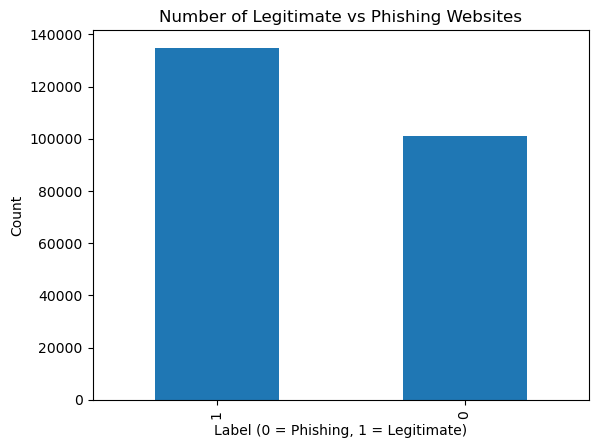

In [28]:
df['label'].value_counts().plot(kind='bar')
plt.title('Number of Legitimate vs Phishing Websites')
plt.xlabel('Label (0 = Phishing, 1 = Legitimate)')
plt.ylabel('Count')
plt.show()

In [29]:
# Use percentile to filter out extreme outliers just for visualization
for col in ['URLLength', 'LineOfCode', 'NoOfImage', 'NoOfJS']:
    upper_limit = df[col].quantile(0.95)  # look at the bottom 95% of data
    print(col, "95th percentile value:", upper_limit)

URLLength 95th percentile value: 73.0
LineOfCode 95th percentile value: 4391.0
NoOfImage 95th percentile value: 96.0
NoOfJS 95th percentile value: 38.0


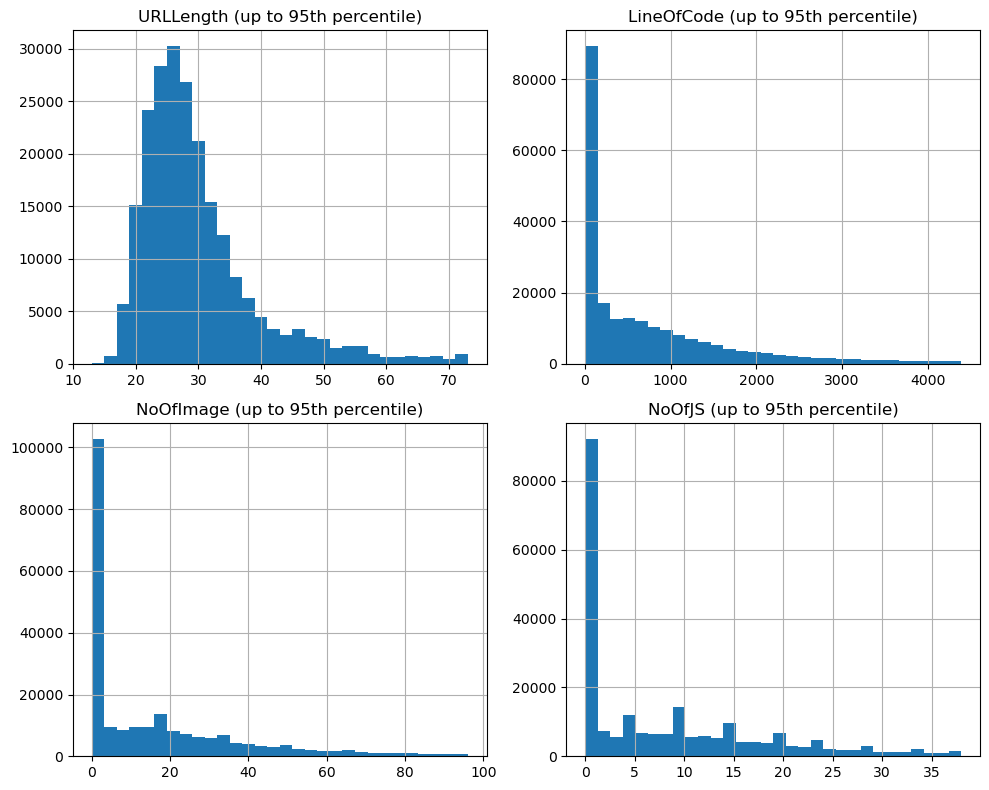

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

df[df['URLLength'] <= 73]['URLLength'].hist(bins=30, ax=axes[0, 0])
axes[0, 0].set_title('URLLength (up to 95th percentile)')

df[df['LineOfCode'] <= 4391]['LineOfCode'].hist(bins=30, ax=axes[0, 1])
axes[0, 1].set_title('LineOfCode (up to 95th percentile)')

df[df['NoOfImage'] <= 96]['NoOfImage'].hist(bins=30, ax=axes[1, 0])
axes[1, 0].set_title('NoOfImage (up to 95th percentile)')

df[df['NoOfJS'] <= 38]['NoOfJS'].hist(bins=30, ax=axes[1, 1])
axes[1, 1].set_title('NoOfJS (up to 95th percentile)')

plt.tight_layout()
plt.show()

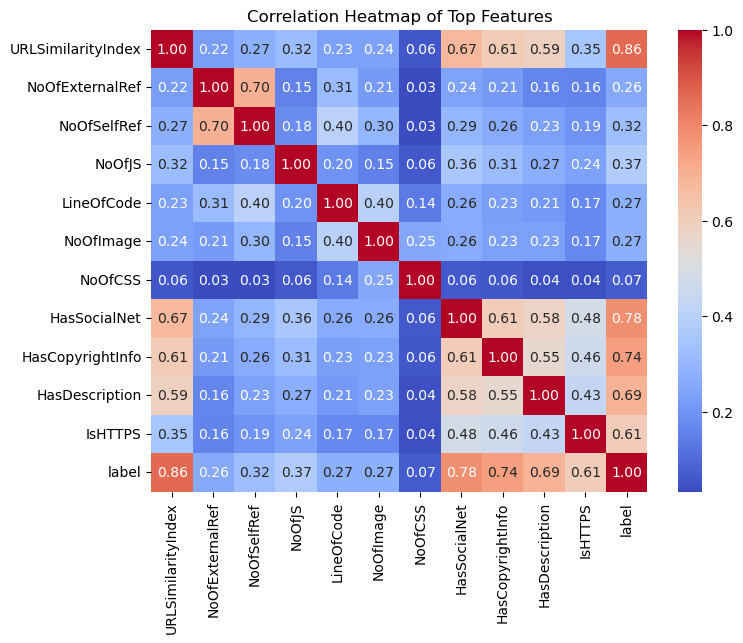

In [31]:
import seaborn as sns

top_features = ['URLSimilarityIndex', 'NoOfExternalRef', 'NoOfSelfRef', 'NoOfJS',
                'LineOfCode', 'NoOfImage', 'NoOfCSS', 'HasSocialNet',
                'HasCopyrightInfo', 'HasDescription', 'IsHTTPS', 'label']

correlation_matrix = df[top_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Top Features')
plt.show()

# Step 8 Decision Tree

In [32]:
from sklearn.tree import DecisionTreeClassifier

# Build the model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train_scaled, y_train)

print("Training done!")

Training done!


In [33]:
# Predict using test data
y_pred_dt = dt_model.predict(X_test_scaled)

# Print the 4 metrics
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [34]:
comparison = pd.DataFrame({
    'Model': ['Random Forest', 'Decision Tree'],
    'Accuracy': [accuracy_score(y_test, y_pred), accuracy_score(y_test, y_pred_dt)],
    'Precision': [precision_score(y_test, y_pred), precision_score(y_test, y_pred_dt)],
    'Recall': [recall_score(y_test, y_pred), recall_score(y_test, y_pred_dt)],
    'F1 Score': [f1_score(y_test, y_pred), f1_score(y_test, y_pred_dt)]
})

print(comparison)

           Model  Accuracy  Precision  Recall  F1 Score
0  Random Forest       1.0        1.0     1.0       1.0
1  Decision Tree       1.0        1.0     1.0       1.0


In [35]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [36]:
model = keras.Sequential([
    layers.Dense(64, activation='relu', input_shape=(51,)),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.summary()

C:\Users\CHIN KANG JIE\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,441 (21.25 KB)

 Trainable params: 5,441 (21.25 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled!")

Model compiled!


In [ ]:
history = model.fit(
    X_train_scaled, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/20
4716/4716 ━━━━━━━━━━━━━━━━━━━━ 31s 6ms/step - accuracy: 0.9988 - loss: 0.0044 - val_accuracy: 0.9998 - val_loss: 6.6299e-04
Epoch 2/20
4716/4716 ━━━━━━━━━━━━━━━━━━━━ 19s 4ms/step - accuracy: 0.9999 - loss: 4.1880e-04 - val_accuracy: 0.9998 - val_loss: 6.9656e-04
Epoch 3/20
4708/4716 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9999 - loss: 3.0461e-04

In [ ]:
plt.figure(figsize=(12, 5))

# Plot accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Step 1: Get probability predictions from the ANN
y_pred_ann_prob = model.predict(X_test_scaled)

# Step 2: Convert probabilities to 0/1 labels (threshold = 0.5)
y_pred_ann = (y_pred_ann_prob > 0.5).astype(int)

# Step 3: Print the 4 metrics
print("Accuracy:", accuracy_score(y_test, y_pred_ann))
print("Precision:", precision_score(y_test, y_pred_ann))
print("Recall:", recall_score(y_test, y_pred_ann))
print("F1 Score:", f1_score(y_test, y_pred_ann))

In [ ]:
# Create a comparison table of all 3 models
comparison_all = pd.DataFrame({
    'Model': ['Random Forest', 'Decision Tree', 'ANN (Deep Learning)'],
    'Accuracy': [
        accuracy_score(y_test, y_pred), 
        accuracy_score(y_test, y_pred_dt), 
        accuracy_score(y_test, y_pred_ann)
    ],
    'Precision': [
        precision_score(y_test, y_pred), 
        precision_score(y_test, y_pred_dt), 
        precision_score(y_test, y_pred_ann)
    ],
    'Recall': [
        recall_score(y_test, y_pred), 
        recall_score(y_test, y_pred_dt), 
        recall_score(y_test, y_pred_ann)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred), 
        f1_score(y_test, y_pred_dt), 
        f1_score(y_test, y_pred_ann)
    ]
})

print(comparison_all)

In [ ]:
cm = confusion_matrix(y_test, y_pred_ann)
print(cm)

In [ ]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Phishing (0)', 'Legitimate (1)'],
            yticklabels=['Phishing (0)', 'Legitimate (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - ANN')
plt.show()

In [ ]:
import joblib

# Save the trained Random Forest model
joblib.dump(rf_model, 'rf_model.joblib')

# Save the scaler as well (needed to transform new data the same way)
joblib.dump(scaler, 'scaler.joblib')

print("Model and scaler saved!")

In [ ]:
# Number of subdomains = total parts - 2 (main domain + TLD)
no_of_subdomain = len(domain_parts) - 2
print("Number of Subdomains:", no_of_subdomain)

In [ ]:
import requests

test_url = "https://www.wikipedia.org"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
}

response = requests.get(test_url, headers=headers, timeout=10)

print("Status Code:", response.status_code)
print("Content Length:", len(response.text))

In [ ]:
from bs4 import BeautifulSoup

# Parse the HTML content
soup = BeautifulSoup(response.text, 'html.parser')

# Count the number of images
no_of_image = len(soup.find_all('img'))
print("Number of Images:", no_of_image)

# Count the number of JS files
no_of_js = len(soup.find_all('script'))
print("Number of JS:", no_of_js)

# Count the number of CSS files
no_of_css = len(soup.find_all('link', rel='stylesheet'))
print("Number of CSS:", no_of_css)

In [ ]:
# Count the number of lines in the HTML source code
line_of_code = len(response.text.split('\n'))
print("Line of Code:", line_of_code)

In [ ]:
# 继续用上面已经抓好的 soup 和 response
# HasTitle（网页有没有标题？）
has_title = 1 if soup.find('title') else 0
print("Has Title:", has_title)

# LargestLineLength（最长的一行 HTML 有多少字）
lines = response.text.split('\n')
largest_line_length = max(len(line) for line in lines)
print("Largest Line Length:", largest_line_length)

# HasFavicon（有没有网站小图标）
favicon = soup.find('link', rel=lambda r: r and 'icon' in r)
has_favicon = 1 if favicon else 0
print("Has Favicon:", has_favicon)

# HasDescription（有没有网页描述）
desc = soup.find('meta', attrs={'name': 'description'})
has_description = 1 if desc else 0
print("Has Description:", has_description)

# IsResponsive（有没有手机版支援）
viewport = soup.find('meta', attrs={'name': 'viewport'})
is_responsive = 1 if viewport else 0
print("Is Responsive:", is_responsive)

# Robots（有没有 robots 指令）
robots_tag = soup.find('meta', attrs={'name': 'robots'})
has_robots = 1 if robots_tag else 0
print("Robots:", has_robots)

# HasSubmitButton
has_submit = 1 if soup.find('input', {'type': 'submit'}) or soup.find('button') else 0
print("Has Submit Button:", has_submit)

# HasHiddenFields
has_hidden = 1 if soup.find('input', {'type': 'hidden'}) else 0
print("Has Hidden Fields:", has_hidden)

# HasPasswordField
has_password = 1 if soup.find('input', {'type': 'password'}) else 0
print("Has Password Field:", has_password)

# NoOfiFrame
no_of_iframe = len(soup.find_all('iframe'))
print("No Of iFrame:", no_of_iframe)

# NoOfPopup（JS 里有几个 window.open）
scripts_text = ' '.join(s.string for s in soup.find_all('script') if s.string)
no_of_popup = scripts_text.count('window.open')
print("No Of Popup:", no_of_popup)

# HasExternalFormSubmit（form 有没有把资料送到外部网站）
domain_check = urlparse(test_url).netloc
has_external_form = 0
for form in soup.find_all('form', action=True):
    action = form['action']
    if action.startswith('http') and domain_check not in action:
        has_external_form = 1
        break
print("Has External Form Submit:", has_external_form)

# HasSocialNet（有没有社群媒体连结）
social_keywords = ['facebook', 'twitter', 'instagram', 'youtube', 'linkedin']
all_links = [a.get('href', '') for a in soup.find_all('a', href=True)]
has_social = 1 if any(kw in link for link in all_links for kw in social_keywords) else 0
print("Has Social Net:", has_social)

# HasCopyrightInfo
page_text = soup.get_text().lower()
has_copyright = 1 if '©' in page_text or 'copyright' in page_text else 0
print("Has Copyright Info:", has_copyright)

# Bank / Pay / Crypto（URL 或标题有没有这些关键字）
title_text = soup.find('title').get_text().lower() if soup.find('title') else ''
combined = (test_url + title_text).lower()
bank   = 1 if 'bank' in combined else 0
pay    = 1 if 'pay' in combined else 0
crypto = 1 if any(k in combined for k in ['crypto', 'bitcoin', 'wallet']) else 0
print("Bank:", bank, "| Pay:", pay, "| Crypto:", crypto)

# NoOfSelfRef / NoOfExternalRef / NoOfEmptyRef（链接分类）
self_ref = external_ref = empty_ref = 0
for a in soup.find_all('a', href=True):
    href = a['href']
    if href in ('', '#'):
        empty_ref += 1
    elif href.startswith('http') and domain_check not in href:
        external_ref += 1
    else:
        self_ref += 1
print("Self Ref:", self_ref)
print("External Ref:", external_ref)
print("Empty Ref:", empty_ref)

# NoOfURLRedirect（meta refresh 跳转）
meta_refresh = soup.find('meta', attrs={'http-equiv': 'refresh'})
no_of_redirect = 1 if meta_refresh else 0
print("No Of URL Redirect:", no_of_redirect)

# NoOfSelfRedirect（JS 里 location.href 的次数）
no_of_self_redirect = scripts_text.count('location.href')
print("No Of Self Redirect:", no_of_self_redirect)

In [ ]:
import joblib
import pandas as pd

# Load model
rf_model = joblib.load('rf_model.joblib')
scaler = joblib.load('scaler.joblib')

# Combine features (order must match training)
features = {
    'URLLength': url_length,
    'DomainLength': len(parsed.netloc),
    'IsDomainIP': 0,
    'URLSimilarityIndex': 100,
    'CharContinuationRate': sum(1 for i in range(1, len(test_url)) if test_url[i].isalpha() != test_url[i-1].isalpha()) / len(test_url),
    'TLDLegitimateProb': 0.5,
    'URLCharProb': -sum((test_url.count(c)/len(test_url)) * __import__('math').log2(test_url.count(c)/len(test_url)) for c in set(test_url)),
    'TLDLength': len(parsed.netloc.split('.')[-1]),
    'NoOfSubDomain': no_of_subdomain,
    'HasObfuscation': 0,
    'NoOfObfuscatedChar': 0,
    'ObfuscationRatio': 0,
    'NoOfLettersInURL': sum(c.isalpha() for c in test_url),
    'LetterRatioInURL': sum(c.isalpha() for c in test_url) / len(test_url),
    'NoOfDegitsInURL': no_of_digits,
    'DegitRatioInURL': no_of_digits / len(test_url),
    'NoOfEqualsInURL': test_url.count('='),
    'NoOfQMarkInURL': test_url.count('?'),
    'NoOfAmpersandInURL': test_url.count('&'),
    'NoOfOtherSpecialCharsInURL': len([c for c in test_url if c not in 'abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789=?&.:/\\-_~#@%']),
    'SpacialCharRatioInURL': len([c for c in test_url if not c.isalnum()]) / len(test_url),
    'IsHTTPS': is_https,
    'LineOfCode': line_of_code,
    'LargestLineLength': largest_line_length,
    'HasTitle': has_title,
    'DomainTitleMatchScore': 0,
    'URLTitleMatchScore': 0,
    'HasFavicon': has_favicon,
    'Robots': has_robots,
    'IsResponsive': is_responsive,
    'NoOfURLRedirect': no_of_redirect,
    'NoOfSelfRedirect': no_of_self_redirect,
    'HasDescription': has_description,
    'NoOfPopup': no_of_popup,
    'NoOfiFrame': no_of_iframe,
    'HasExternalFormSubmit': has_external_form,
    'HasSocialNet': has_social,
    'HasSubmitButton': has_submit,
    'HasHiddenFields': has_hidden,
    'HasPasswordField': has_password,
    'Bank': bank,
    'Pay': pay,
    'Crypto': crypto,
    'HasCopyrightInfo': has_copyright,
    'NoOfImage': no_of_image,
    'NoOfCSS': no_of_css,
    'NoOfJS': no_of_js,
    'NoOfSelfRef': self_ref,
    'NoOfEmptyRef': empty_ref,
    'NoOfExternalRef': external_ref,
    'TLD_encoded': 0,          # <-- moved to last
}

# Predict
feature_df = pd.DataFrame([features])
feature_scaled = scaler.transform(feature_df)
prediction = rf_model.predict(feature_scaled)[0]

print("URL:", test_url)
if prediction == 1:
    print("Prediction: Legitimate Website")
else:
    print("Prediction: Phishing Website")

In [ ]:
import re
# Test with multiple URL
test_urls = [
    "https://www.google.com",
    "https://www.maybank2u.com.my",
    "http://login-paypal-secure-account.xyz",
    "http://192.168.1.1/admin",
]

for url in test_urls:
    test_url = url
    parsed = urlparse(test_url)
    
    # Recalculate URL features
    url_length = len(test_url)
    is_https = 1 if test_url.startswith('https') else 0
    no_of_digits = sum(c.isdigit() for c in test_url)
    no_of_subdomain = max(len(parsed.netloc.split('.')) - 2, 0)
    is_domain_ip = 1 if re.match(r'^\d{1,3}(\.\d{1,3}){3}$', parsed.netloc) else 0

    features['URLLength'] = url_length
    features['IsHTTPS'] = is_https
    features['NoOfDegitsInURL'] = no_of_digits
    features['NoOfSubDomain'] = no_of_subdomain
    features['IsDomainIP'] = is_domain_ip
    features['NoOfLettersInURL'] = sum(c.isalpha() for c in test_url)
    features['LetterRatioInURL'] = features['NoOfLettersInURL'] / len(test_url)
    features['DegitRatioInURL'] = no_of_digits / len(test_url)

    feature_df = pd.DataFrame([features])
    feature_scaled = scaler.transform(feature_df)
    prediction = rf_model.predict(feature_scaled)[0]
    prob = rf_model.predict_proba(feature_scaled)[0]

    result = "Legitimate" if prediction == 1 else "Phishing"
    print(f"{url}")
    print(f"  → {result} (Phishing: {round(prob[0]*100)}% | Legitimate: {round(prob[1]*100)}%)")
    print()